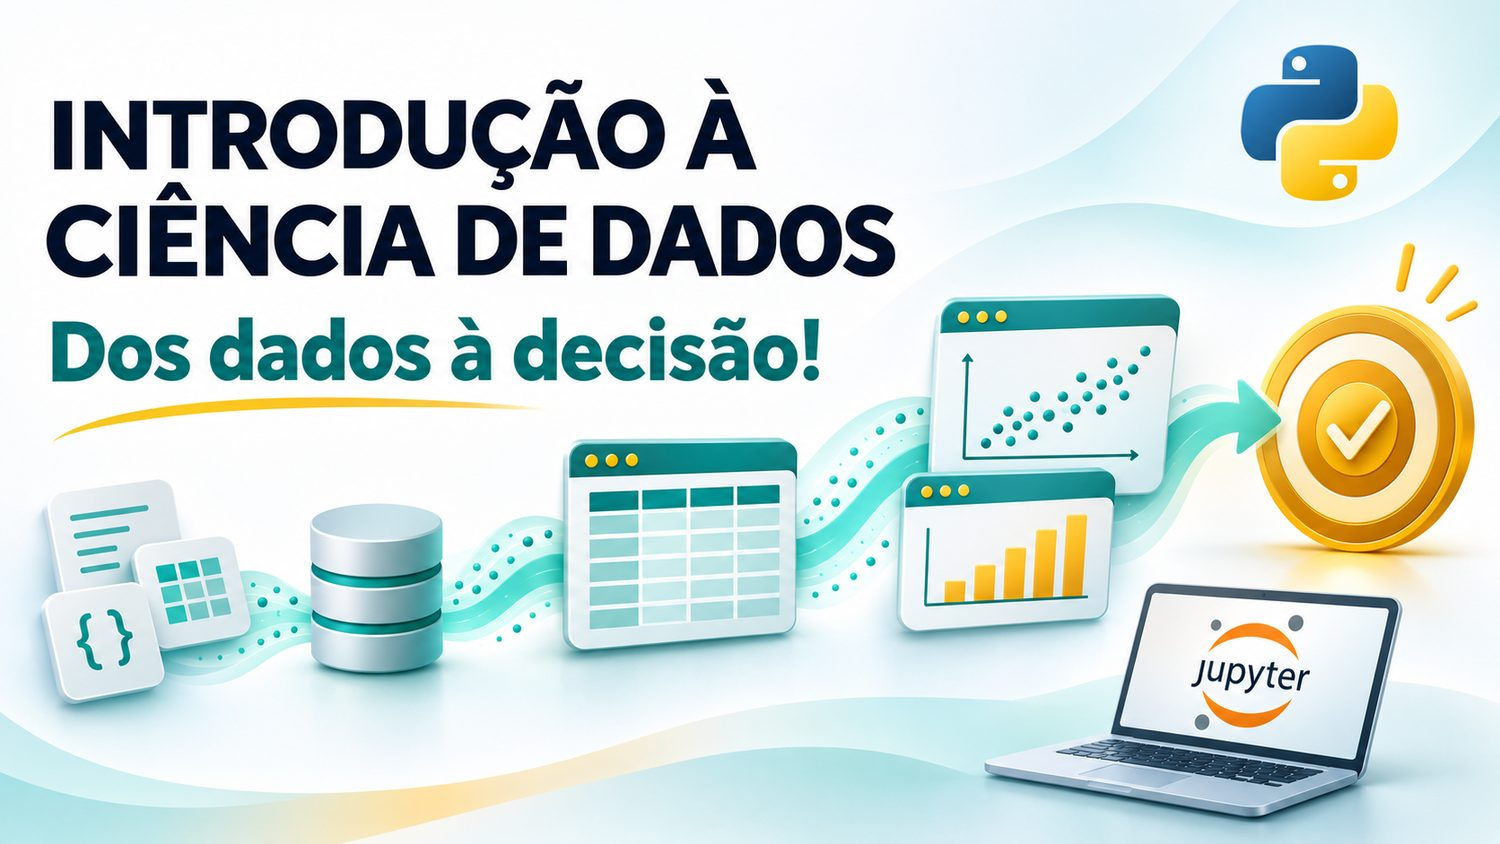

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_supervisionados/06_Validacao_Cruzada.ipynb)

# Capítulo 6 – Validação cruzada e escolha de hiperparâmetros

Até aqui escolhemos k e a profundidade com **um** conjunto de validação. Funciona, mas o resultado depende de que entregas calharam nesse conjunto. A **validação cruzada** resolve o problema usando todos os dados de treino para validar, por turnos. Este capítulo implementa-a de raiz, usa-a para escolher hiperparâmetros e mostra o erro mais frequente: deixar informação da validação entrar na preparação.

> **Objetivos:** perceber porque uma única divisão dá uma estimativa instável; implementar a validação cruzada com K partes; interpretar a média e a dispersão dos resultados; conhecer as variantes (estratificada, por grupos, temporal); procurar hiperparâmetros com uma grelha; evitar fugas pondo toda a preparação dentro do pipeline; seguir o protocolo completo até ao teste final.

**Pré-requisitos:** capítulos 1 a 5, e os capítulos 2 e 6 do módulo 4. A sintaxe está em [Scikit-Learn: aplicações](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_05_ScikitLearn_Aplicacoes.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


## O problema: uma divisão é um sorteio

Guardamos 20% das entregas para o teste final. Com as restantes, repetimos 40 vezes a divisão em treino e validação, mudando só a semente, e avaliamos **sempre o mesmo modelo**.

Desenvolvimento (treino + validação): 3200 entregas | Teste, guardado até ao fim: 800


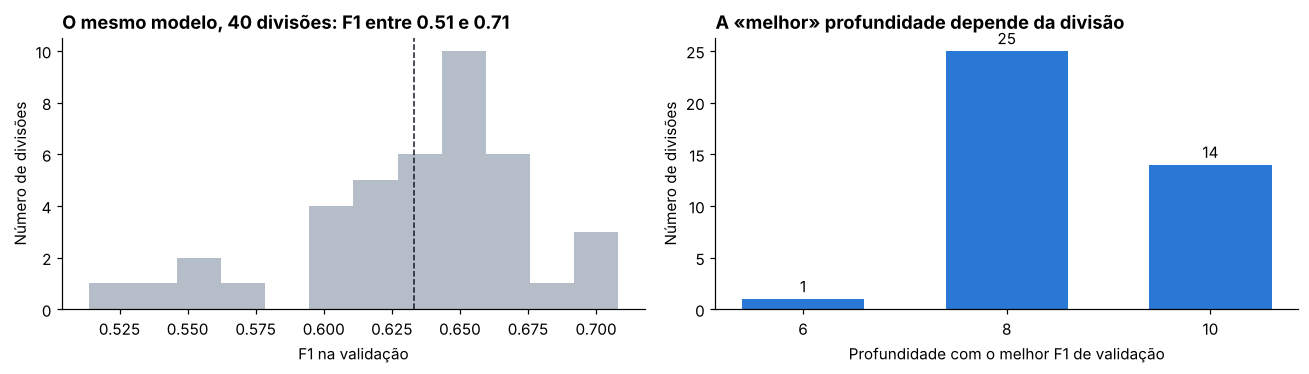

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
todas = numericas + nominais
desenvolvimento, teste = train_test_split(entregas, test_size=0.2, random_state=3, stratify=entregas["atrasada"])
X, y = desenvolvimento[todas], desenvolvimento["atrasada"]
print(f"Desenvolvimento (treino + validação): {len(desenvolvimento)} entregas | Teste, guardado até ao fim: {len(teste)}")


def arvore(**opcoes):
    preparacao = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), nominais)], remainder="passthrough")
    return make_pipeline(preparacao, DecisionTreeClassifier(random_state=0, **opcoes))


resultados, escolhas = [], []
for semente in range(40):
    X_t, X_v, y_t, y_v = train_test_split(X, y, test_size=0.25, random_state=semente, stratify=y)
    f1_por_profundidade = {p: f1_score(y_v, arvore(max_depth=p, min_samples_leaf=10).fit(X_t, y_t).predict(X_v)) for p in [3, 4, 5, 6, 8, 10]}
    resultados.append(f1_por_profundidade[6])
    escolhas.append(max(f1_por_profundidade, key=f1_por_profundidade.get))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.hist(resultados, bins=12, color=CINZA)
ax1.axvline(np.mean(resultados), color=TINTA, ls="--", lw=1)
ax1.set_xlabel("F1 na validação")
ax1.set_ylabel("Número de divisões")
ax1.set_title(f"O mesmo modelo, 40 divisões: F1 entre {min(resultados):.2f} e {max(resultados):.2f}")
contagem = pd.Series(escolhas).value_counts().sort_index()
barras = ax2.bar(contagem.index.astype(str), contagem, color=AZUL, width=0.6)
ax2.bar_label(barras, padding=2)
ax2.set_xlabel("Profundidade com o melhor F1 de validação")
ax2.set_ylabel("Número de divisões")
ax2.set_title("A «melhor» profundidade depende da divisão")
plt.tight_layout()
plt.show()

O modelo é exatamente o mesmo em todas as repetições (uma árvore de profundidade 6), e o F1 de validação varia bastante só porque mudaram as entregas que ficaram de fora. À direita, a consequência: a profundidade «vencedora» muda de divisão para divisão.

Com uma só divisão, estamos a tirar **um** valor desta distribuição, sem saber se calhou alto ou baixo. As diferenças pequenas entre modelos que vimos nos capítulos anteriores podiam ser apenas isto.

## A ideia: todos validam, por turnos

Na **validação cruzada com K partes** (*K-fold cross-validation*):

1. baralham-se os dados e dividem-se em K partes iguais;
2. treina-se com K − 1 partes e valida-se na que ficou de fora;
3. repete-se K vezes, de modo que **cada parte sirva de validação exatamente uma vez**;
4. o resultado é a **média** das K avaliações.

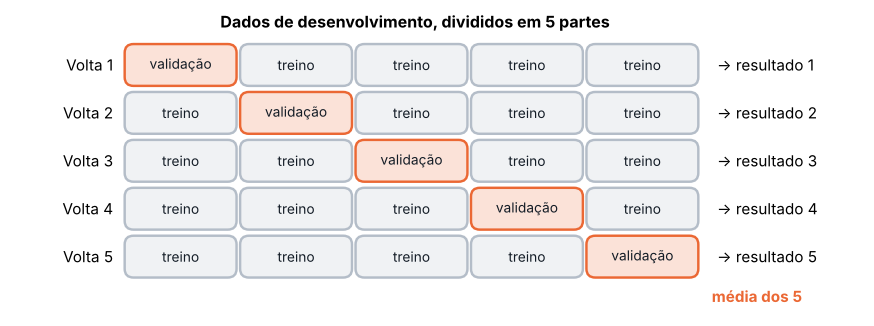

In [4]:
K = 5
fig, ax = tela(10.4, 3.6, tamanho=(10, 3.6))
for volta in range(K):
    for parte in range(K):
        validacao_aqui = parte == volta
        caixa(ax, 2.1 + parte * 1.3, 2.75 - volta * 0.55, 1.22, 0.44, "validação" if validacao_aqui else "treino",
              cor=LARANJA if validacao_aqui else CINZA, tamanho=9)
    ax.text(1.95, 2.97 - volta * 0.55, f"Volta {volta + 1}", ha="right", va="center", fontsize=10)
    ax.text(8.75, 2.97 - volta * 0.55, f"→ resultado {volta + 1}", ha="left", va="center", fontsize=10)
ax.text(5.35, 3.4, "Dados de desenvolvimento, divididos em 5 partes", ha="center", fontsize=10.5, fontweight="bold")
ax.text(9.2, 0.25, "média dos 5", ha="center", fontsize=10, fontweight="bold", color=LARANJA)
ax.set_xlim(0.8, 10.4)
ax.set_ylim(0.1, 3.6)
plt.show()

Cada entrega é usada para validar uma vez e para treinar K − 1 vezes. Nenhuma avaliação é feita com dados que o modelo viu no treino dessa volta.

### Implementar de raiz

In [5]:
def partes_k(n, k, semente=0):
    """Baralha as posições 0..n-1 e divide-as em k partes de tamanho quase igual."""
    posicoes = np.random.default_rng(semente).permutation(n)
    return np.array_split(posicoes, k)


def validacao_cruzada(criar_modelo, X, y, k=5, metrica=f1_score, semente=0):
    """Devolve a métrica obtida em cada uma das k voltas."""
    partes = partes_k(len(X), k, semente)
    resultados = []
    for volta in range(k):
        validar = partes[volta]
        treinar = np.concatenate([partes[i] for i in range(k) if i != volta])
        modelo = criar_modelo().fit(X.iloc[treinar], y.iloc[treinar])        # um modelo novo em cada volta
        resultados.append(metrica(y.iloc[validar], modelo.predict(X.iloc[validar])))
    return np.array(resultados)


f1_voltas = validacao_cruzada(lambda: arvore(max_depth=6, min_samples_leaf=10), X, y, k=5)
print("F1 em cada volta:", f1_voltas.round(3))
print(f"Média: {f1_voltas.mean():.3f} | desvio-padrão: {f1_voltas.std():.3f}")

F1 em cada volta: [0.615 0.662 0.642 0.624 0.667]
Média: 0.642 | desvio-padrão: 0.020


Três pormenores do código que importam:

- em cada volta cria-se um **modelo novo**. Reutilizar o da volta anterior deixaria passar informação;
- as partes são feitas **uma vez**, antes do ciclo, para que não se sobreponham;
- o resultado são K números. A **média** é a estimativa do desempenho; o **desvio-padrão** diz quanto ela oscila de uma parte para outra.

No scikit-learn, o mesmo faz-se com `cross_val_score`:

In [6]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

oficial = cross_val_score(arvore(max_depth=6, min_samples_leaf=10), X, y, cv=KFold(5, shuffle=True, random_state=0), scoring="f1")
print("scikit-learn, F1 em cada volta:", oficial.round(3), f"| média {oficial.mean():.3f}")

scikit-learn, F1 em cada volta: [0.614 0.5   0.694 0.726 0.623] | média 0.632


As partes não são as mesmas (o baralhamento é diferente), e por isso os valores de cada volta diferem dos nossos; a média fica próxima.

### É mais estável?

Repetimos a experiência do início: 40 sementes, agora com validação cruzada de 5 partes em vez de uma divisão.

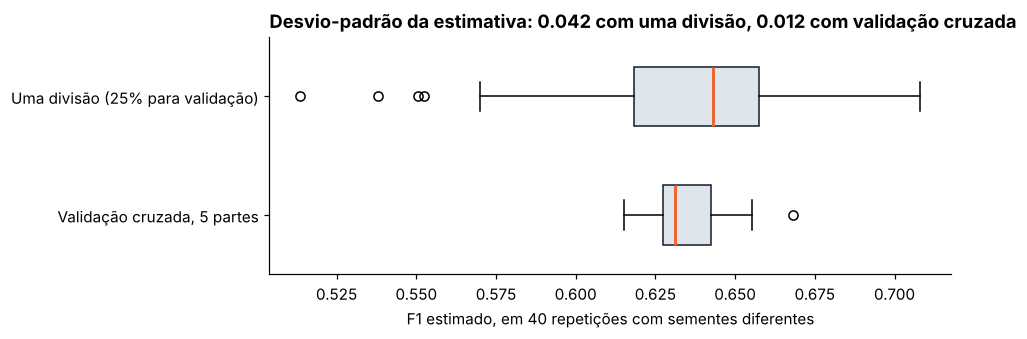

In [7]:
cruzadas = [cross_val_score(arvore(max_depth=6, min_samples_leaf=10), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), scoring="f1").mean() for s in range(40)]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.boxplot([resultados, cruzadas], orientation="horizontal", widths=0.5, tick_labels=["Uma divisão (25% para validação)", "Validação cruzada, 5 partes"],
           patch_artist=True, boxprops={"facecolor": "#dfe5ec", "edgecolor": TINTA}, medianprops={"color": LARANJA, "linewidth": 2})
ax.invert_yaxis()
ax.set_xlabel("F1 estimado, em 40 repetições com sementes diferentes")
ax.set_title(f"Desvio-padrão da estimativa: {np.std(resultados):.3f} com uma divisão, {np.std(cruzadas):.3f} com validação cruzada")
plt.show()

A estimativa por validação cruzada oscila muito menos: cada uma é a média de cinco avaliações, que entre todas usam **todas** as entregas de desenvolvimento.

O preço é o tempo: treinam-se K modelos em vez de um.

## Quantas partes? E que tipo de partes?

| K | Treina-se com | Vantagem | Desvantagem |
| --- | --- | --- | --- |
| 3 | 67% dos dados | Rápido | Cada modelo vê menos dados; estimativa pessimista |
| **5 ou 10** | 80% ou 90% | O compromisso habitual | 5 a 10 vezes mais lento do que uma divisão |
| n (*leave-one-out*) | Todos menos um | Usa quase todos os dados | Muito lento; n modelos |

A forma de fazer as partes segue a regra do capítulo 2 do módulo 4: **a validação deve imitar a utilização real do modelo**.

| Variante | Quando usar | No scikit-learn |
| --- | --- | --- |
| **Estratificada** | Classificação, sobretudo com classes raras: cada parte mantém a proporção das classes | `StratifiedKFold` |
| **Por grupos** | Várias linhas da mesma entidade (o mesmo cliente, o mesmo doente): o grupo fica inteiro numa parte | `GroupKFold` |
| **Temporal** | Dados com ordem no tempo: treina-se com o passado e valida-se no futuro | `TimeSeriesSplit` |
| **Repetida** | Poucos dados: repete-se a validação cruzada com vários baralhamentos | `RepeatedStratifiedKFold` |

Com 14% de atrasos, uma parte feita ao acaso pode ficar com poucos. Usamos a versão estratificada daqui em diante.

In [8]:
simples = [y.iloc[parte].mean() for parte in partes_k(len(y), 10)]
estratificada = [y.iloc[v].mean() for _, v in StratifiedKFold(10, shuffle=True, random_state=0).split(X, y)]
print("Percentagem de atrasos em cada uma de 10 partes")
print("  ao acaso:      ", " ".join(f"{p:5.1%}" for p in simples))
print("  estratificadas:", " ".join(f"{p:5.1%}" for p in estratificada))

Percentagem de atrasos em cada uma de 10 partes
  ao acaso:       13.1% 11.2% 12.8% 14.4% 15.3% 15.9% 14.4% 14.7% 14.1% 18.8%
  estratificadas: 14.4% 14.4% 14.4% 14.4% 14.4% 14.4% 14.4% 14.7% 14.7% 14.7%


## Escolher hiperparâmetros com validação cruzada

Agora podemos refazer a escolha da profundidade com uma estimativa mais fiável. Para cada valor, calculamos a média e o desvio-padrão do F1 nas 5 voltas.

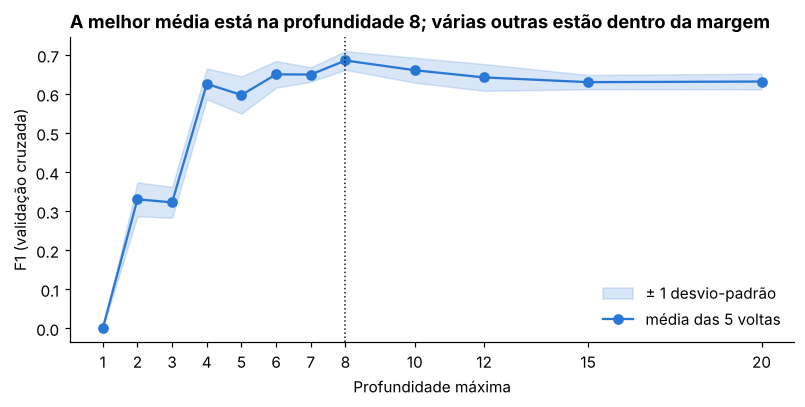

In [9]:
partes = StratifiedKFold(5, shuffle=True, random_state=0)
profundidades = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20]
curva = pd.DataFrame([{"profundidade": p, **dict(zip(["média", "desvio"], (lambda v: (v.mean(), v.std()))(
    cross_val_score(arvore(max_depth=p), X, y, cv=partes, scoring="f1"))))} for p in profundidades]).set_index("profundidade")
melhor = int(curva["média"].idxmax())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(curva.index, curva["média"] - curva["desvio"], curva["média"] + curva["desvio"], color=AZUL, alpha=0.18, label="± 1 desvio-padrão")
ax.plot(curva.index, curva["média"], "o-", color=AZUL, label="média das 5 voltas")
ax.axvline(melhor, color=TINTA, ls=":", lw=1)
ax.set_xticks(profundidades)
ax.set_xlabel("Profundidade máxima")
ax.set_ylabel("F1 (validação cruzada)")
ax.set_title(f"A melhor média está na profundidade {melhor}; várias outras estão dentro da margem")
ax.legend(frameon=False, loc="lower right")
plt.show()

A faixa azul mostra a incerteza. Há um conjunto de profundidades cujas faixas se sobrepõem: **os dados não permitem distinguir entre elas**. Quando assim é, uma regra sensata é ficar com o modelo **mais simples** entre os que estão empatados com o melhor: é mais fácil de explicar e tem menos variância.

### Vários hiperparâmetros: a procura em grelha

Uma árvore tem mais do que um hiperparâmetro, e eles interagem. A **procura em grelha** experimenta todas as combinações de uma lista de valores, cada uma avaliada por validação cruzada.

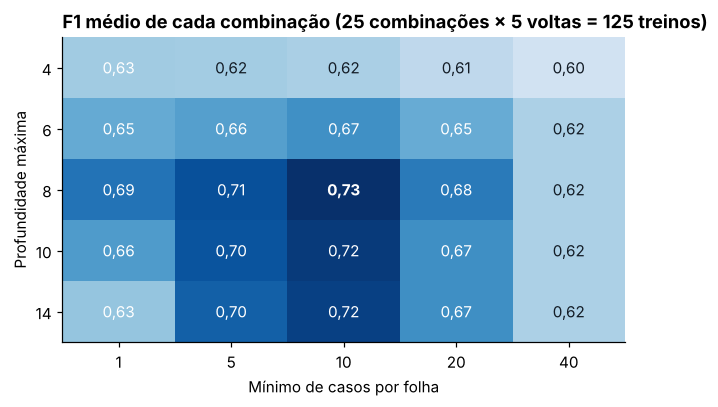

Melhor combinação: {'max_depth': 8, 'min_samples_leaf': 10} | F1 médio: 0.727


In [10]:
from sklearn.model_selection import GridSearchCV

grelha = {"decisiontreeclassifier__max_depth": [4, 6, 8, 10, 14], "decisiontreeclassifier__min_samples_leaf": [1, 5, 10, 20, 40]}
procura = GridSearchCV(arvore(), grelha, cv=partes, scoring="f1").fit(X, y)
tabela = pd.DataFrame(procura.cv_results_).pivot(index="param_decisiontreeclassifier__max_depth", columns="param_decisiontreeclassifier__min_samples_leaf", values="mean_test_score")

fig, ax = plt.subplots(figsize=(6.6, 3.6))
imagem = ax.imshow(tabela, cmap="Blues", aspect="auto", vmin=tabela.min().min() - 0.03)
for i in range(tabela.shape[0]):
    for j in range(tabela.shape[1]):
        valor = tabela.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}".replace(".", ","), ha="center", va="center", color="white" if valor > tabela.stack().quantile(0.3) else TINTA,
                fontweight="bold" if valor == tabela.max().max() else "normal")
ax.set_xticks(range(tabela.shape[1]), tabela.columns)
ax.set_yticks(range(tabela.shape[0]), tabela.index)
ax.set_xlabel("Mínimo de casos por folha")
ax.set_ylabel("Profundidade máxima")
ax.grid(False)
ax.set_title("F1 médio de cada combinação (25 combinações × 5 voltas = 125 treinos)")
plt.show()

print("Melhor combinação:", {k.split("__")[1]: v for k, v in procura.best_params_.items()}, f"| F1 médio: {procura.best_score_:.3f}")

O nome `decisiontreeclassifier__max_depth` indica «o parâmetro `max_depth` do passo `decisiontreeclassifier` do pipeline»: o nome do passo, dois sublinhados e o nome do parâmetro.

Depois da procura, o `GridSearchCV` **volta a treinar** a melhor combinação com todos os dados de desenvolvimento. O modelo final fica em `procura.best_estimator_`.

O custo cresce depressa: 5 valores de um hiperparâmetro × 5 de outro × 5 voltas são 125 treinos. Com muitos hiperparâmetros, usa-se uma **procura aleatória** (`RandomizedSearchCV`), que experimenta um número fixo de combinações tiradas ao acaso.

## A fuga que estraga tudo: preparar antes de dividir

No módulo 4 vimos a regra: tudo o que se **aprende** com os dados (médias, escalas, categorias, escolha de atributos) aprende-se só com o treino. Na validação cruzada, «o treino» muda em cada volta. A preparação tem por isso de ser refeita **dentro de cada volta**.

Uma experiência mostra o que acontece quando não se faz assim. Criamos dados de **puro ruído**: 100 observações, 2 000 atributos aleatórios e um alvo tirado à sorte. Não há nada para aprender; a exatidão honesta é 50%.

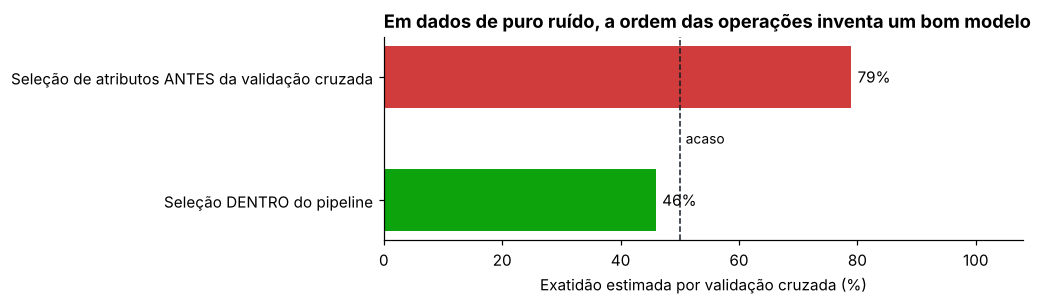

In [11]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(1)
X_ruido, y_ruido = rng.normal(size=(100, 2000)), rng.integers(0, 2, 100)
partes_ruido = StratifiedKFold(5, shuffle=True, random_state=0)

# ERRADO: escolher os 20 «melhores» atributos com todos os dados, e só depois validar
X_escolhidos = SelectKBest(f_classif, k=20).fit_transform(X_ruido, y_ruido)
errado = cross_val_score(KNeighborsClassifier(5), X_escolhidos, y_ruido, cv=partes_ruido).mean()

# CERTO: a escolha dos atributos faz parte do pipeline e é refeita em cada volta
certo = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), KNeighborsClassifier(5)), X_ruido, y_ruido, cv=partes_ruido).mean()

fig, ax = plt.subplots(figsize=(7.5, 2.4))
barras = ax.barh(["Seleção de atributos ANTES da validação cruzada", "Seleção DENTRO do pipeline"], [errado * 100, certo * 100], color=[MAU, BOM], height=0.5)
ax.bar_label(barras, fmt="%.0f%%", padding=4)
ax.axvline(50, color=TINTA, ls="--", lw=1)
ax.text(51, 0.5, "acaso", fontsize=9, va="center")
ax.invert_yaxis()
ax.set_xlim(0, 108)
ax.set_xlabel("Exatidão estimada por validação cruzada (%)")
ax.set_title("Em dados de puro ruído, a ordem das operações inventa um bom modelo")
plt.show()

Com a seleção feita antes, a validação cruzada anuncia um modelo muito bom em dados onde **não existe relação nenhuma**. Entre 2 000 colunas aleatórias há sempre algumas que, por acaso, acompanham o alvo nestas 100 observações. Ao escolhê-las com todos os dados, as observações de validação já participaram na escolha.

Com a seleção dentro do pipeline, cada volta escolhe os atributos só com o seu treino, e o resultado é o que devia ser: o acaso.

> **Tudo o que olha para os dados entra no pipeline:** imputação, normalização, codificação, seleção de atributos, criação de atributos com parâmetros aprendidos. O pipeline inteiro é que vai para a validação cruzada.

Na nossa árvore, a preparação (codificar a zona e o veículo) já está dentro do pipeline, e por isso os resultados acima são honestos.

## O protocolo completo

Juntando tudo o que vimos neste módulo e no anterior:

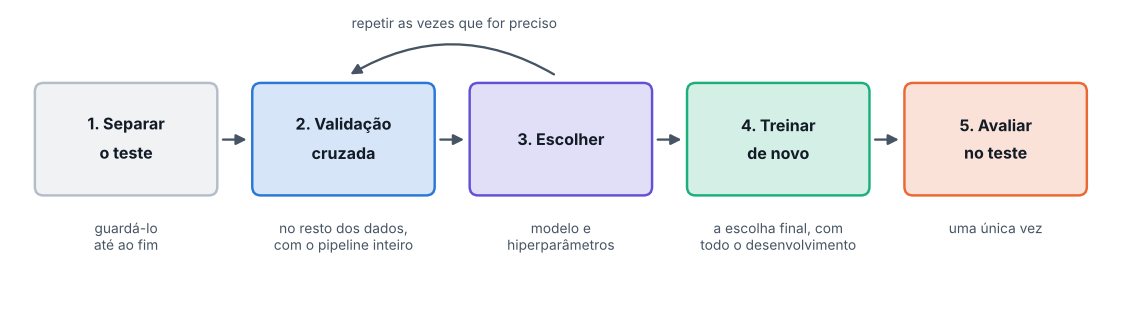

In [12]:
fig, ax = tela(13, 3.6, tamanho=(13, 3.5))
passos = [("1. Separar\no teste", "guardá-lo\naté ao fim", CINZA), ("2. Validação\ncruzada", "no resto dos dados,\ncom o pipeline inteiro", AZUL),
          ("3. Escolher", "modelo e\nhiperparâmetros", VIOLETA), ("4. Treinar\nde novo", "a escolha final, com\ntodo o desenvolvimento", VERDE),
          ("5. Avaliar\nno teste", "uma única vez", LARANJA)]
for i, (titulo, detalhe, cor) in enumerate(passos):
    caixa(ax, 0.3 + i * 2.55, 1.5, 2.1, 1.25, titulo, cor=cor, tamanho=10.5, negrito=True)
    ax.text(1.35 + i * 2.55, 1.2, detalhe, ha="center", va="top", fontsize=9, color="#465463")
    if i < len(passos) - 1:
        seta(ax, (2.45 + i * 2.55, 2.12), (2.8 + i * 2.55, 2.12))
seta(ax, (6.4, 2.85), (3.95, 2.85), connectionstyle="arc3,rad=0.3")
ax.text(5.2, 3.4, "repetir as vezes que for preciso", ha="center", fontsize=9, color="#465463")
ax.set_ylim(0.2, 3.6)
plt.show()

Os passos 2 e 3 podem repetir-se à vontade. O passo 5 faz-se **uma vez**: se o resultado do teste for usado para voltar atrás e mudar o modelo, o teste passa a ser mais uma validação e deixa de dar uma estimativa honesta.

Aplicamos às entregas, comparando três famílias de modelos com as mesmas partes.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


def com_escala(modelo, colunas_numericas=numericas, colunas_nominais=nominais):
    transformadores = [("num", StandardScaler(), colunas_numericas)] + ([("cat", OneHotEncoder(handle_unknown="ignore"), colunas_nominais)] if colunas_nominais else [])
    return make_pipeline(ColumnTransformer(transformadores), modelo)


procuras = {"Regressão logística": GridSearchCV(com_escala(LogisticRegression(max_iter=2000)), {"logisticregression__C": [0.1, 1, 10]}, cv=partes, scoring="f1"),
            "KNN (distância e hora)": GridSearchCV(com_escala(KNeighborsClassifier(), ["distancia_km", "hora"], []), {"kneighborsclassifier__n_neighbors": [5, 9, 15, 25, 41]}, cv=partes, scoring="f1"),
            "Árvore de decisão": procura}
linhas = []
for nome, p in procuras.items():
    if not hasattr(p, "best_score_"):
        p.fit(X, y)
    linhas.append({"Modelo": nome, "melhor configuração": ", ".join(f"{k.split('__')[1]} = {v}" for k, v in p.best_params_.items()),
                   "F1 médio (validação cruzada)": p.best_score_, "desvio-padrão": p.cv_results_["std_test_score"][p.best_index_]})
comparacao = pd.DataFrame(linhas).set_index("Modelo")
comparacao.round(3)

,melhor configuração,F1 médio (validação cruzada),desvio-padrão
Modelo,,,
Regressão logística,C = 10,0.121,0.044
KNN (distância e hora),n_neighbors = 5,0.491,0.033
Árvore de decisão,"max_depth = 8, min_samples_leaf = 10",0.727,0.058


A diferença entre a árvore e os outros dois modelos é várias vezes maior do que os desvios-padrão: não é um acaso da divisão. Escolhemos a árvore, e só agora abrimos o teste.

In [14]:
from sklearn.metrics import precision_score, recall_score

final = procura.best_estimator_                                  # já treinado de novo com todo o desenvolvimento
previsto = final.predict(teste[todas])
f1_teste = f1_score(teste["atrasada"], previsto)
print(f"F1 na validação cruzada: {procura.best_score_:.3f} (± {procura.cv_results_['std_test_score'][procura.best_index_]:.3f})")
print(f"F1 no teste:             {f1_teste:.3f}   | sensibilidade {recall_score(teste['atrasada'], previsto):.1%} | precisão {precision_score(teste['atrasada'], previsto):.1%}")

F1 na validação cruzada: 0.727 (± 0.058)
F1 no teste:             0.697   | sensibilidade 66.4% | precisão 73.3%


O resultado do teste deve ficar perto do da validação cruzada. É normal que fique um pouco **abaixo**: o valor da validação cruzada que apresentamos é o **melhor de 25 combinações**, e parte dessa vantagem é sorte. Quanto mais combinações se experimentam, mais otimista fica o melhor resultado. É por isso que o teste existe.

O próprio teste é uma amostra: com 800 entregas e pouco mais de uma centena de atrasos, o seu F1 também oscila alguns pontos conforme as entregas que lá calharam. Um teste pequeno dá uma estimativa honesta, mas pouco precisa.

## Exercícios

### `Exercício 1` – Contar treinos

Queres escolher entre 4 valores de `max_depth`, 3 de `min_samples_leaf` e 2 de `criterion`, com validação cruzada de 10 partes. Quantos modelos são treinados no total, contando com o treino final?

<details>
<summary><b>Ver uma solução possível</b></summary>

4 × 3 × 2 = 24 combinações. Cada uma é treinada 10 vezes: 240 treinos. Mais um treino final da melhor combinação com todos os dados: **241**.

</details>

### `Exercício 2` – O efeito de K

Usa a função `validacao_cruzada` para avaliar a árvore de profundidade 6 (com `min_samples_leaf=10`) com K = 2, 5, 10 e 20. Para cada K, mostra a média e o desvio-padrão do F1. O que acontece à dispersão entre voltas quando K aumenta, e porquê?

In [15]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for k in [2, 5, 10, 20]:
    v = validacao_cruzada(lambda: arvore(max_depth=6, min_samples_leaf=10), X, y, k=k)
    print(f"K = {k:>2}: média {v.mean():.3f} | desvio-padrão entre voltas {v.std():.3f} | entregas por parte: {len(X) // k}")
```

A média muda pouco. O desvio-padrão **entre voltas** aumenta com K: cada parte de validação é mais pequena (com K = 20, cerca de 160 entregas e pouco mais de 20 atrasos), e o F1 calculado com tão poucos casos oscila mais. A média das K voltas continua estável, porque junta mais avaliações.

</details>

### `Exercício 3` – Validação cruzada para a regressão

Avalia por validação cruzada de 5 partes (`KFold`, não estratificada) uma `DecisionTreeRegressor` com `min_samples_leaf=10`, para as profundidades 4, 6, 8, 10 e 12, com o alvo `tempo_min`. Usa `scoring="neg_mean_absolute_error"`. Porque é que os valores vêm negativos?

In [16]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.tree import DecisionTreeRegressor

for p in [4, 6, 8, 10, 12]:
    modelo = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(), nominais)], remainder="passthrough"), DecisionTreeRegressor(max_depth=p, min_samples_leaf=10, random_state=0))
    v = -cross_val_score(modelo, X, desenvolvimento["tempo_min"], cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_absolute_error")
    print(f"profundidade {p:>2}: MAE {v.mean():.2f} ± {v.std():.2f} min")
```

O scikit-learn segue a convenção de que **maior é sempre melhor**, para poder escolher o máximo em qualquer procura. Um erro é melhor quando é menor, e por isso é devolvido com o sinal trocado. Basta multiplicar por −1.

</details>

### `Exercício 4` – Normalizar antes ou dentro?

Com as entregas, compara duas formas de avaliar um KNN (k = 15) com as cinco colunas numéricas: (a) normalizar todo o `X` com `StandardScaler` e depois fazer a validação cruzada; (b) pôr o `StandardScaler` num pipeline. A diferença é grande? Porque é que aqui a fuga quase não se nota, ao contrário do exemplo do ruído?

In [17]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
Xn = X[numericas].astype(float)
a = cross_val_score(KNeighborsClassifier(15), StandardScaler().fit_transform(Xn), y, cv=partes, scoring="roc_auc").mean()
b = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(15)), Xn, y, cv=partes, scoring="roc_auc").mean()
print(f"(a) antes: {a:.4f} | (b) dentro: {b:.4f}")
```

Os dois valores são quase iguais. A média e o desvio-padrão de milhares de entregas mal mudam por incluir ou não uma parte delas, e não usam o alvo. A fuga existe, mas é minúscula. No exemplo do ruído, a seleção de atributos **usava o alvo** e havia poucas observações: as condições em que a fuga é grave. Como não é fácil saber de antemão quando vai ser grave, a regra é pôr sempre tudo no pipeline.

</details>

## Verifica o que aprendeste

- [ ] Sei porque uma única divisão dá uma estimativa instável.
- [ ] Sei descrever e implementar a validação cruzada com K partes.
- [ ] Sei interpretar a média e o desvio-padrão dos resultados.
- [ ] Sei quando usar partes estratificadas, por grupos ou temporais.
- [ ] Sei usar o `GridSearchCV` e ler os seus resultados.
- [ ] Sei porque a preparação tem de estar dentro do pipeline.
- [ ] Sei descrever o protocolo completo, do teste guardado à avaliação final.
- [ ] Sei porque o melhor resultado de uma procura é otimista.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/cross_validation.html
- https://scikit-learn.org/stable/modules/grid_search.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://en.wikipedia.org/wiki/Cross-validation_(statistics)